### 1. İlk önce gerekli olan kütüphaneleri ekledim.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 2. Veri Setinin Yüklenmesi ve Genel İnceleme

Öncelikle, ai4i2020.csv adlı veri setini pandas kütüphanesi kullanarak içeri aktardım. Bunun için pd.read_csv fonksiyonunu kullandım. Daha sonra, veri setimin genel yapısını anlamak adına data.info() komutuyla veri setindeki sütunların adlarını, veri tiplerini ve eksik değer olup olmadığını kontrol ettim. Son olarak, veri setimin ilk birkaç satırını incelemek için data.head() fonksiyonunu çağırarak genel bir fikir edindim.

In [2]:
data = pd.read_csv("ai4i2020.csv")# Veri setini bu kod satırı ile yüklememiz gerekmektedir.

# Veri setinin genel bilgilerini incelemek 
data.info()  # Sütunların tiplerini ve eksik değerleri kontrol etmek için bu kod yazılır.
data.head()  # İlk 5 satırı görüntülemek için bu kod yazılır.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### 3. Veri Setinin Gerekli Kısmının Seçilmesi

Veri setimde 2500 ile 7500 arasındaki verileri kullanmam gerekiyor. 
Pythonda indekslerin 0 dan başladığını bildiğim için, bu aralığı doğru bir şekilde belirtmek adına 2499:7500 yazdım. 
Bu işlemi iloc fonksiyonunu kullanarak gerçekleştirdim.

Sonrasında, oluşan yeni veri setimin yapısını ve boyutunu kontrol etmek için data.info() komutunu kullandım. Ayrıca, ilk birkaç satırını görmek amacıyla data.head() fonksiyonunu çağırarak, işlemin doğru çalışıp çalışmadığını kontrol ettim.

In [3]:
data = data.iloc[2499:7500] # Veri setinin 2500 ile 7500 arasındaki satırlarını seçtim

data.info() #veri setimin boutunu kontrol etmek için 
data.head() #ilk bir kaç satırı bu komut ile görüntüledim.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5001 entries, 2499 to 7499
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      5001 non-null   int64  
 1   Product ID               5001 non-null   object 
 2   Type                     5001 non-null   object 
 3   Air temperature [K]      5001 non-null   float64
 4   Process temperature [K]  5001 non-null   float64
 5   Rotational speed [rpm]   5001 non-null   int64  
 6   Torque [Nm]              5001 non-null   float64
 7   Tool wear [min]          5001 non-null   int64  
 8   Machine failure          5001 non-null   int64  
 9   TWF                      5001 non-null   int64  
 10  HDF                      5001 non-null   int64  
 11  PWF                      5001 non-null   int64  
 12  OSF                      5001 non-null   int64  
 13  RNF                      5001 non-null   int64  
dtypes: float64(3), int64(

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
2499,2500,M17359,M,299.1,308.9,1325,48.4,220,0,0,0,0,0,0
2500,2501,L49680,L,299.1,308.9,1617,32.3,223,0,0,0,0,0,0
2501,2502,M17361,M,299.1,308.9,1476,42.7,225,0,0,0,0,0,0
2502,2503,L49682,L,299.2,309.0,1515,48.9,228,1,0,0,0,1,0
2503,2504,L49683,L,299.2,309.0,1408,47.2,0,0,0,0,0,0,0


### 4. Gereksiz Sütunların Kaldırılması

Veri setimde modelleme için gerekli olmayan sütunları temizlemek istedim. Özellikle UDI, Product ID ve Type sütunlarının analiz ve modelleme süreci için bir katkısı olmadığını düşündüm. Bu sütunları kaldırmak için pandas'ın drop fonksiyonunu kullandım ve columns parametresine kaldırmak istediğim sütunların isimlerini liste olarak verdim.

Bu işlemden sonra, güncellenmiş veri setimin ilk birkaç satırını incelemek için data.head() komutunu çalıştırdım. Böylece, istediğim sütunların başarılı bir şekilde kaldırıldığından emin oldum.

In [4]:
data = data.drop(columns=["UDI", "Product ID", "Type"])

data.head() # Güncellenmiş veri setini kontrol ettim.


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
2499,299.1,308.9,1325,48.4,220,0,0,0,0,0,0
2500,299.1,308.9,1617,32.3,223,0,0,0,0,0,0
2501,299.1,308.9,1476,42.7,225,0,0,0,0,0,0
2502,299.2,309.0,1515,48.9,228,1,0,0,0,1,0
2503,299.2,309.0,1408,47.2,0,0,0,0,0,0,0


### 5. Bağımsız ve Bağımlı Değişkenlerin Ayrıştırılması

Veri setimde modelleme için bağımsız ve bağımlı değişkenleri ayırmak istedim. Bu amaçla, bağımsız değişkenler (X) için analiz ve tahmin sürecinde etkili olacağını düşündüğüm sütunları seçtim: Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm] ve Tool wear [min].

Bağımlı değişken (y) olarak ise, tahmin etmek istediğim Machine failure sütununu belirledim.

Sonrasında, veri boyutlarının doğru şekilde ayrıştırıldığını kontrol etmek için X.shape ve y.shape komutlarıyla bağımsız ve bağımlı değişkenlerin boyutlarını yazdırdım. Bu, işlemin başarılı bir şekilde tamamlanıp tamamlanmadığını anlamama yardımcı oldu.

In [5]:
# Bağımsız değişkenler (X) ve bağımlı değişken (y) ayrıştırılması için aşağıdaki kodları kullandım.
X = data[["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]]
y = data["Machine failure"]

# Verilerin boyutlarını kontrol etmek için;
print("Bağımsız değişkenlerin boyutu:", X.shape)
print("Bağımlı değişkenin boyutu:", y.shape)


Bağımsız değişkenlerin boyutu: (5001, 5)
Bağımlı değişkenin boyutu: (5001,)


### 6. Veri Setinin Eğitim ve Test Olarak Ayrılması

Modelimi eğitmek ve test etmek için verileri eğitim ve test setlerine ayırmam gerekti. Bunun için scikit-learn kütüphanesinin `train_test_split` fonksiyonunu kullandım. `test_size=0.2` parametresiyle verinin %20'ini test seti olarak ayırdım, geri kalan %80'i ise eğitim seti oldu. Ayrıca, `random_state=42` parametresini belirleyerek sonuçların tekrarlanabilir olmasını sağladım.  

Eğitim ve test veri setlerinin boyutlarının doğru şekilde ayrıldığını kontrol etmek için `X_train.shape` ve `X_test.shape` komutlarıyla her iki veri setinin boyutlarını yazdırdım.

In [6]:
# Eğitim ve test veri setlerine ayrılması
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Ayrılan veri setlerini kontrol etme
print("Eğitim verisinin boyutu:", X_train.shape)
print("Test verisinin boyutu:", X_test.shape)


Eğitim verisinin boyutu: (4000, 5)
Test verisinin boyutu: (1001, 5)


### 7. Sınıf Dengesizliğini SMOTE ile Düzeltme ve SVC Modelini Geliştirme


İlk olarak, gerekli kütüphaneleri import ettim. `SVC` (Support Vector Classifier) modelini kullanarak sınıflandırma işlemi yapacağım. Ayrıca, sınıf dengesizliğini gidermek için `SMOTE` (Synthetic Minority Over-sampling Technique) yöntemini kullanacağım. Bunun için `sklearn.svm` ve `imblearn.over_sampling` kütüphanelerini kullandım. `pandas` ve `matplotlib` kütüphaneleri de veri işleme ve görselleştirme işlemleri için gereklidir.

Veri setimdeki sınıf dengesizliğini gidermek amacıyla, `SMOTE` kullanarak eğitim verisini dengeliyorum. `fit_resample` fonksiyonu ile dengesiz eğitim veri setini dengelemiş oldum. Ardından, SMOTE sonrası eğitim verisinin sınıf dağılımını kontrol ederek, dengesizliğin giderilip giderilmediğini kontrol ettim.

Sonrasında, `SVC` modelini eğittim ve `smote` ile dengelenmiş veriyi kullanarak modelimi eğittim. Modeli eğitim verisiyle eğittikten sonra, test verisi üzerinde tahminler yaparak sonuçları değerlendirdim.

Modelin performansını `accuracy_score` fonksiyonu ile doğruluk oranını hesaplayarak ölçtüm ve `classification_report` fonksiyonu ile detaylı sınıflandırma raporunu yazdırdım.

Son olarak, dengesizliği gidermenin ardından oluşan yeni sınıf dağılımını görselleştirmek istedim. Bu işlemi bar grafiği ile gösterdim, böylece SMOTE sonrası sınıfların nasıl dengelendiğini görsel olarak da gözlemledim.

SMOTE sonrası eğitim seti sınıf dağılımı:
 Machine failure
0    3820
1    3820
Name: count, dtype: int64
SMOTE Uygulandıktan Sonra SVC Doğruluk Oranı: 0.7962037962037962

SMOTE Uygulandıktan Sonra SVC Sınıflandırma Raporu:
               precision    recall  f1-score   support

           0       0.99      0.79      0.88       961
           1       0.15      0.85      0.25        40

    accuracy                           0.80      1001
   macro avg       0.57      0.82      0.57      1001
weighted avg       0.96      0.80      0.86      1001



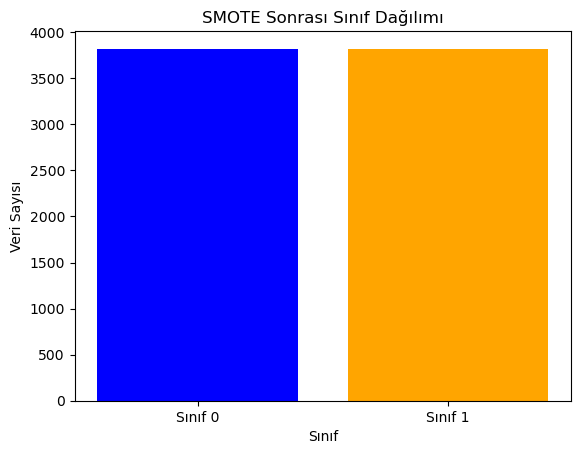

In [7]:

# 7.1. Gerekli kütüphanelerin eklenmesi
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import SMOTE
import pandas as pd

# 7.2. SMOTE ile sınıf dengesizliğini giderme
# SMOTE işlemini uyguluyoruz.
smote = SMOTE(random_state=42) # SMOTE nesnesi oluşturulur ve random_state ile tekrarlanabilirlik sağlanır.
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train) # SMOTE ile eğitim verisini dengeliyoruz

# SMOTE sonrası veri setinin sınıf dağılımını kontrol ediyor.
print("SMOTE sonrası eğitim seti sınıf dağılımı:\n", pd.Series(y_train_sm).value_counts()) # Dengelenmiş veri setinin sınıf dağılımını yazdırdım.

# 7.3. SVC Modeli Eğitimi
# SMOTE ile dengelenmiş veri seti kullanılarak model eğitiliyor.
svc_model_smote = SVC(random_state=42) #Bu kod satırı SVC modelini oluşturur
svc_model_smote.fit(X_train_sm, y_train_sm)  # SMOTE ile dengelenmiş veri ile modelimi eğittim.

# 7.4. Test Verisi Üzerinde Tahmin Yapma
# Modeli test verisi üzerinde değerlendiriyoruz.
y_pred_smote = svc_model_smote.predict(X_test)  # Test verisi üzerinde tahminler yaptı.

# 7.5. Model Performansı Değerlendirme
# Doğruluk oranını hesaplama ve sınıflandırma raporunu yazdırma.
print("SMOTE Uygulandıktan Sonra SVC Doğruluk Oranı:", accuracy_score(y_test, y_pred_smote)) #Bu kod satırı ile doğruluk oranını hesapladım.
print("\nSMOTE Uygulandıktan Sonra SVC Sınıflandırma Raporu:\n", classification_report(y_test, y_pred_smote)) # Detaylı sınıflandırma raporunu yazdırdım.


# 7.6. Ekstra Analiz: Sınıf Dağılımı Görselleştirme (Opsiyonel)
import matplotlib.pyplot as plt

# Sınıfların dağılımını bar grafiği ile gösteririz.
plt.bar(['Sınıf 0', 'Sınıf 1'], pd.Series(y_train_sm).value_counts(), color=['blue', 'orange'])
plt.title("SMOTE Sonrası Sınıf Dağılımı") # Grafiğe başlık ekliyoruz
plt.xlabel("Sınıf") # X eksenini etiketliyoruz
plt.ylabel("Veri Sayısı") # Y eksenini etiketliyoruz
plt.show() # Grafiği ekranda gösteriyoruz


### 8. Logistic Regression Modeli ile İlgili Kodlama

Öncelikle, Logistic Regression modelini scikit-learn kütüphanesinden import ettim. Ardından, SMOTE ile dengelenmiş eğitim setini kullanarak modelimi eğittim. Modelin eğitimini yaparken, `random_state=42` parametresiyle sonuçların tekrarlanabilir olmasını sağladım ve `max_iter=1000` parametresiyle modelin 1000 iterasyon boyunca eğitilmesini sağladım. Eğitim işlemi tamamlandıktan sonra, test verisi üzerinde tahminler yaptım ve sonuçları `y_pred_lr` değişkeninde sakladım. Modelin performansını değerlendirmek için doğruluk oranını hesapladım ve yazdırdım. Bunun yanı sıra, daha detaylı bir değerlendirme için `classification_report` fonksiyonunu kullanarak sınıflandırma raporunu oluşturup yazdırdım. Son olarak, SVC modeliyle Logistic Regression modelini karşılaştırmak için her iki modelin doğruluk oranlarını hesapladım ve sonuçları yazdırarak hangi modelin daha iyi performans gösterdiğini gördüm.

In [8]:
# 8.1. Logistic Regression Kütüphanesinin Eklenmesi
from sklearn.linear_model import LogisticRegression # Logistic Regression modelini scikit-learn kütüphanesinden içe aktarıyorum

# 8.2. Logistic Regression Modeli Eğitimi
# SMOTE ile dengelenmiş eğitim seti kullanılarak model eğitiliyor.
lr_model = LogisticRegression(random_state=42, max_iter=1000) # Logistic Regression modelini oluşturuyorum, max_iter=1000 parametresi ile iterasyon sayısını belirliyorum.
lr_model.fit(X_train_sm, y_train_sm) # SMOTE ile dengelenmiş eğitim verisini kullanarak modeli eğitiyorum.

# 8.3. Test Verisi Üzerinde Tahmin Yapma
# Logistic Regression modelinin test verisi üzerindeki tahminlerini alıyoruz.
y_pred_lr = lr_model.predict(X_test)  # Eğitimli modeli test verisi üzerinde tahmin yapmak için kullanıyorum

# 8.4. Model Performansı Değerlendirme
# Doğruluk oranı ve sınıflandırma raporu ile değerlendirme.
from sklearn.metrics import classification_report, accuracy_score  # Model performansını değerlendirmek için gerekli metrikleri içe aktarıyorum.


print("Logistic Regression Doğruluk Oranı:", accuracy_score(y_test, y_pred_lr)) # Logistic Regression modelinin doğruluk oranını yazdırıyorum.
print("\nLogistic Regression Sınıflandırma Raporu:\n", classification_report(y_test, y_pred_lr)) # Sınıflandırma raporunu yazdırıyorum.

# 8.5. Modellerin Karşılaştırması 
# SVC ve Logistic Regression doğruluk oranlarını karşılaştırıyoruz.
svc_accuracy = accuracy_score(y_test, y_pred_smote) # SVC modelinin doğruluk oranını hesaplıyorum.
lr_accuracy = accuracy_score(y_test, y_pred_lr) # Logistic Regression modelinin doğruluk oranını hesaplıyorum.

print(f"SVC Modeli Doğruluk Oranı: {svc_accuracy}")  # SVC modelinin doğruluk oranını yazdırıyorum. 
print(f"Logistic Regression Doğruluk Oranı: {lr_accuracy}")  # Logistic Regression modelinin doğruluk oranını yazdırıyorum.


Logistic Regression Doğruluk Oranı: 0.8311688311688312

Logistic Regression Sınıflandırma Raporu:
               precision    recall  f1-score   support

           0       0.99      0.83      0.90       961
           1       0.16      0.78      0.27        40

    accuracy                           0.83      1001
   macro avg       0.58      0.80      0.59      1001
weighted avg       0.96      0.83      0.88      1001

SVC Modeli Doğruluk Oranı: 0.7962037962037962
Logistic Regression Doğruluk Oranı: 0.8311688311688312


### 9. Grafiksel Karşılaştırma: SVC ve Logistic Regression Modelleri

Bu kodda, iki modelin doğruluk oranları ve F1-skorlarını karşılaştırmak için grafikler oluşturdum. İlk olarak, SVC (SMOTE) ve Logistic Regression modellerinin doğruluk oranlarını içeren bir bar grafiği çizdim. `models` ve `accuracies` listelerini kullanarak her iki modelin doğruluk oranlarını görselleştirdim ve her bir barın üzerine doğruluk oranlarını yazdım. Grafiğin başlığını "Modellerin Doğruluk Oranlarının Karşılaştırması" olarak belirledim ve Y eksenine "Doğruluk Oranı" etiketi ekledim. Ayrıca, Y ekseninin 0 ile 1 arasında olmasını sağlayarak doğruluk oranlarını net bir şekilde görselleştirdim.

Daha sonra, her iki modelin F1-skorlarını karşılaştırmak için `precision_recall_fscore_support()` fonksiyonunu kullandım. `average="weighted"` parametresi ile sınıf ağırlıklı F1-skorlarını elde ettim ve bu skorları da bir bar grafiği olarak gösterdim. F1-skorları için de her bir barın üzerine skorları yazdım. Son olarak, her iki grafik de `plt.show()` komutuyla görselleştirildi. Bu grafiklerle, modellerin performansını doğruluk oranları ve F1-skorları üzerinden görsel olarak karşılaştırdım.

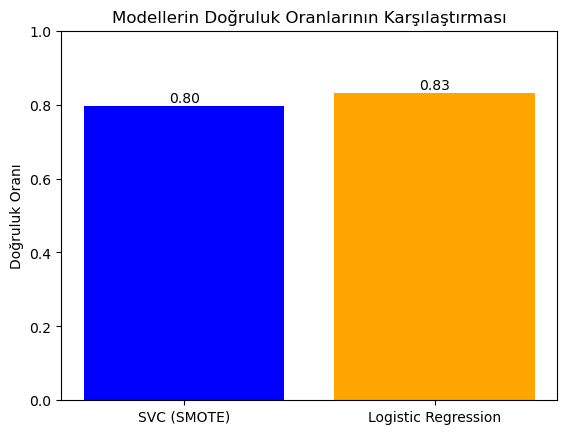

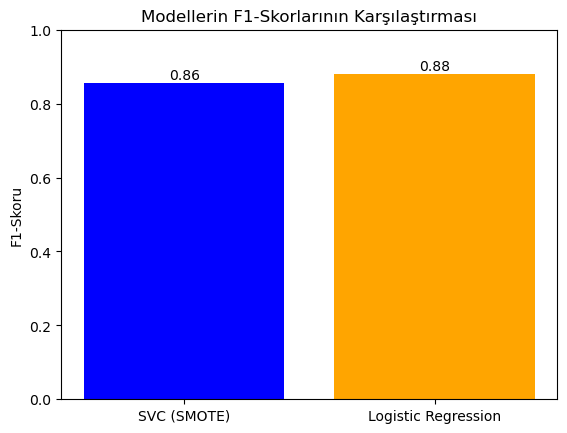

In [9]:
import matplotlib.pyplot as plt

# 9.1. Doğruluk Oranlarının Grafiksel Karşılaştırılması
models = ['SVC (SMOTE)', 'Logistic Regression']
accuracies = [svc_accuracy, lr_accuracy]

plt.bar(models, accuracies, color=['blue', 'orange'])
plt.title("Modellerin Doğruluk Oranlarının Karşılaştırması")
plt.ylabel("Doğruluk Oranı")
plt.ylim(0, 1)
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.01, f"{v:.2f}", ha='center', fontsize=10)
plt.show()

# 9.2. F1-Skorlarının Grafiksel Karşılaştırılması
from sklearn.metrics import precision_recall_fscore_support

svc_f1 = precision_recall_fscore_support(y_test, y_pred_smote, average="weighted")[2]
lr_f1 = precision_recall_fscore_support(y_test, y_pred_lr, average="weighted")[2]

f1_scores = [svc_f1, lr_f1]

plt.bar(models, f1_scores, color=['blue', 'orange'])
plt.title("Modellerin F1-Skorlarının Karşılaştırması")
plt.ylabel("F1-Skoru")
plt.ylim(0, 1)
for i, v in enumerate(f1_scores):
    plt.text(i, v + 0.01, f"{v:.2f}", ha='center', fontsize=10)
plt.show()


### 10. Confusion Matrix ve Hata İncelemesi

Bu kodda, her iki modelin performansını daha ayrıntılı bir şekilde değerlendirebilmek için karışıklık matrislerini (confusion matrix) görselleştirdim. İlk olarak, SVC modeli için karışıklık matrisini hesapladım ve ConfusionMatrixDisplay kullanarak görselleştirdim. cmap="Blues" parametresiyle matrisin renk şemasını mavi tonlarında ayarladım. Bu, karışıklık matrisinin görsel olarak daha anlaşılır olmasını sağladı. Sonrasında, başlık olarak "SVC Modeli - Karışıklık Matrisi" yazısını ekledim ve grafiği görüntüledim.

Ardından, Logistic Regression modeli için aynı işlemi gerçekleştirdim. ConfusionMatrixDisplay ile karışıklık matrisini hesaplayıp görselleştirdim, ancak bu sefer renk şemasını turuncu tonlarında ayarladım (cmap="Oranges"). Başlık olarak "Logistic Regression - Karışıklık Matrisi" yazısını ekleyip bu grafiği de görüntüledim. Bu iki grafik, her iki modelin sınıflandırma doğruluğunu ve hatalarını daha net bir şekilde görmeme yardımcı oldu.

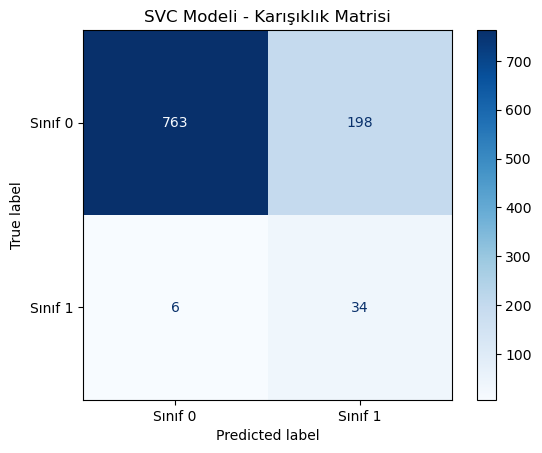

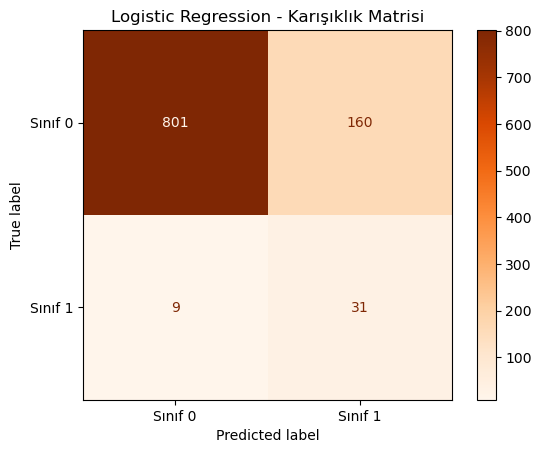

In [10]:
# Gerekli kütüphaneleri içe aktarıyoruz
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 10.1. SVC Modeli için Karışıklık Matrisi
svc_cm = confusion_matrix(y_test, y_pred_smote) # SVC modelinin tahminleri ile gerçek değerleri karşılaştırarak karışıklık matrisini hesapladım.
disp_svc = ConfusionMatrixDisplay(svc_cm, display_labels=["Sınıf 0", "Sınıf 1"]) # Karışıklık matrisini görselleştirmek için ConfusionMatrixDisplay nesnesi oluşturdum.
disp_svc.plot(cmap="Blues") # Karışıklık matrisini mavi renk şemasıyla çiziyorum.
plt.title("SVC Modeli - Karışıklık Matrisi") # Grafiğe başlık ekledim.
plt.show() # Grafiği görüntüledim.

# 10.2. Logistic Regression Modeli için Karışıklık Matrisi
lr_cm = confusion_matrix(y_test, y_pred_lr) # Logistic Regression modelinin tahminleri ile gerçek değerleri karşılaştırarak karışıklık matrisini hesapladım..
disp_lr = ConfusionMatrixDisplay(lr_cm, display_labels=["Sınıf 0", "Sınıf 1"]) # Karışıklık matrisini görselleştirmek için ConfusionMatrixDisplay nesnesi oluşturuyorum..
disp_lr.plot(cmap="Oranges")# Karışıklık matrisini turuncu renk şemasıyla çiziyorum.
plt.title("Logistic Regression - Karışıklık Matrisi") # Grafiğe başlık ekliyorum. 
plt.show() # Grafiği görüntüledim.


### 11. Hiperparametre Optimizasyonu

Bu kodda, SVC (Support Vector Classifier) modelinin hiperparametrelerini optimize etmek için GridSearchCV kullanıyorum. İlk olarak, svc_param_grid adlı bir sözlük oluşturuyorum, burada SVC modelinin ayarlanacak hiperparametrelerini belirliyorum. Bu parametreler, C, kernel ve gamma değerleri için farklı seçenekler içeriyor. Bu hiperparametreler, modelin öğrenme kapasitesini ve doğruluğunu önemli ölçüde etkileyebileceği için, en iyi sonuçları elde etmek amacıyla çeşitli kombinasyonlarını denemek gerekiyor.

Daha sonra, GridSearchCV nesnesini oluşturuyorum. Bu nesne, belirtilen parametre ızgarasında (svc_param_grid) tüm olasılıkları test eder. Ayrıca, 5 katlamalı çapraz doğrulama (cv=5) kullanarak her kombinasyon için modelin doğruluğunu değerlendiriyorum. Doğruluk ölçütü olarak accuracy belirliyorum. 

Son olarak, fit fonksiyonu ile eğitim verisi üzerinde GridSearchCV işlemini başlatıyorum ve modelin en iyi hiperparametrelerini ve elde edilen doğruluk skorunu ekrana yazdırıyorum.

In [11]:
# Gerekli kütüphaneleri import ediyorum
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Veriyi ölçeklendirmek için StandardScaler kullanıyorum
scaler = StandardScaler()

# Eğitim verisini ölçeklendiriyorum
X_train_sm_scaled = scaler.fit_transform(X_train_sm)
X_test_scaled = scaler.transform(X_test)

# SVC Hiperparametre Ayarlarını tanımlıyorum
svc_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

# GridSearchCV ile en iyi parametreleri bulmaya çalışıyorum
svc_grid = GridSearchCV(SVC(random_state=42), svc_param_grid, cv=3, scoring='accuracy', n_jobs=-1) # Paralel işlem için n_jobs=-1 ekliyorum
svc_grid.fit(X_train_sm_scaled, y_train_sm)  # Eğitim verisi üzerinde GridSearchCV'yi çalıştırıyorum

# En iyi parametreleri ve doğruluk oranını yazdırıyorum
print("En İyi SVC Parametreler:", svc_grid.best_params_)
print("En İyi SVC Doğruluk Oranı:", svc_grid.best_score_)


En İyi SVC Parametreler: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
En İyi SVC Doğruluk Oranı: 0.9505223762369317


### 12.  Optimize Edilmiş SVC Modelinin Eğitilmesi ve Test Edilmesi:

Bu kodda, önce GridSearchCV ile en iyi hiperparametreleri bulduğum SVC modelimi optimize ettim. svc_best_model adlı yeni modelimi, GridSearchCV'nin en iyi parametreleriyle eğitim verisi üzerinde (X_train_sm ve y_train_sm) eğittim. Eğitim tamamlandığında, modelimi test verisi üzerinde tahmin yaparak değerlendirdim.

Daha sonra, modelin performansını değerlendirmek için doğruluk oranını hesapladım ve classification_report fonksiyonuyla modelin detaylı performansını (precision, recall, f1-score gibi metrikler) inceledim. Ayrıca, modelin sınıflandırma hatalarını daha iyi anlayabilmek için karışıklık matrisini oluşturup, bunu görselleştirdim.

Optimize Edilmiş SVC Doğruluk Oranı: 0.8061938061938062

Optimize Edilmiş SVC Sınıflandırma Raporu:
               precision    recall  f1-score   support

           0       0.99      0.80      0.89       961
           1       0.15      0.85      0.26        40

    accuracy                           0.81      1001
   macro avg       0.57      0.83      0.57      1001
weighted avg       0.96      0.81      0.86      1001



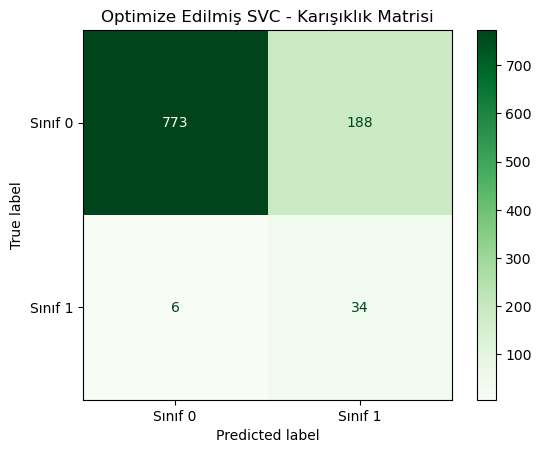

In [12]:
# Optimize edilmiş SVC modelini eğitme
# Burada, GridSearchCV ile en iyi hiperparametreleri bulduğum SVC modelimi, en iyi parametrelerle (svc_grid.best_params_) eğitiyorum.
svc_best_model = SVC(**svc_grid.best_params_, random_state=42)  # Bu kodda en iyi parametrelerle SVC modeli oluşturuyorum.
svc_best_model.fit(X_train_sm, y_train_sm)  # Model, SMOTE ile dengelenmiş eğitim verisi üzerinde eğitiliyor.

# Eğitilen model ile test verisi üzerinde tahmin yapıyorum.
y_pred_best_svc = svc_best_model.predict(X_test)  # Test verisi üzerinde tahminler alınıyor.

# Performans değerlendirme
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Optimize Edilmiş SVC Doğruluk Oranı:", accuracy_score(y_test, y_pred_best_svc))  # Modelin doğruluk oranını hesaplıyorum ve yazdırıyorum.

# Modelin detaylı performansını (precision, recall, f1-score vb.) incelemek için sınıflandırma raporunu yazdırıyorum.
print("\nOptimize Edilmiş SVC Sınıflandırma Raporu:\n", classification_report(y_test, y_pred_best_svc)) 

# Confusion Matrix (Karışıklık Matrisi)
# Karışıklık matrisini hesaplayıp görselleştiriyorum. 
svc_best_cm = confusion_matrix(y_test, y_pred_best_svc)  # Karışıklık matrisi hesaplanıyor.
disp_best_svc = ConfusionMatrixDisplay(svc_best_cm, display_labels=["Sınıf 0", "Sınıf 1"])  # Karışıklık matrisi görselleştiriliyor.
disp_best_svc.plot(cmap="Greens")  # Karışıklık matrisi yeşil tonlarında gösteriliyor.
plt.title("Optimize Edilmiş SVC - Karışıklık Matrisi")  # Grafiğin başlığı ekleniyor.
plt.show()  # Grafik gösteriliyor


### 13. Özellik Önem Düzeyi Analizi:

Bu kodda, SVC modelimdeki özelliklerin önem düzeyini permutation_importance fonksiyonu ile hesaplıyorum. Fonksiyon, her bir özelliği karıştırarak modelin doğruluğundaki değişikliği ölçüyor. Sonrasında, her bir özelliğin önem düzeyini sıralayıp görselleştiriyorum. matplotlib ile yatay bir bar grafiği oluşturarak, her özelliğin model üzerindeki etkisini gösteriyorum. Bu işlem, hangi özelliklerin modelin tahminine daha fazla katkı sağladığını anlamamı sağlıyor.

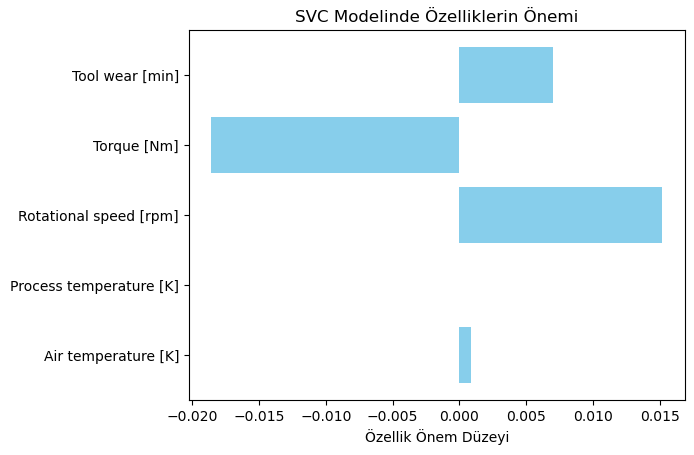

In [13]:
from sklearn.inspection import permutation_importance

# Özelliklerin önem düzeyini hesaplama
result = permutation_importance(svc_best_model, X_test, y_test, n_repeats=10, random_state=42)
importance = result.importances_mean

# Özelliklerin sıralanması ve görselleştirilmesi
features = X.columns
plt.barh(features, importance, color='skyblue')
plt.xlabel("Özellik Önem Düzeyi")
plt.title("SVC Modelinde Özelliklerin Önemi")
plt.show()


### 14. Düşük Önemli Özellikleri Belirleme

Bu kod parçasıyla, verisetimdeki özelliklerin önem derecelerini analiz ederek sıfır veya negatif önem değerine sahip olanları önemsiz olarak tanımlıyor ve tespit ediyorum. Amacım, bu önemsiz özellikleri belirleyip çıkarmak, böylece verisetini optimize ederek gereksiz bilgiden arındırmak ve model performansını artırmak.

In [14]:
# Önemsiz özellikleri belirleme (importance değeri sıfır veya negatif olanlar)
low_importance_features = features[importance <= 0]
print("Çıkarılacak Özellikler:", low_importance_features.tolist())


Çıkarılacak Özellikler: ['Process temperature [K]', 'Torque [Nm]']


### 15. Önemsiz Özellikleri Veri Setinden Çıkarma

Bu kod parçasıyla, daha önce belirlediğim düşük önem düzeyine sahip özellikleri veri setimden çıkarıyorum. Amacım, gereksiz sütunları veri setinden kaldırarak hem eğitim (X_train_sm) hem de test (X_test) veri setlerini optimize etmek. errors='ignore' parametresi sayesinde, çıkarılmak istenen ancak veri setinde bulunmayan sütunlar hata oluşturmadan atlanıyor. Çıkarma işlemi sonrası kalan özellikleri kontrol ederek, veri setimin güncellenmiş durumunu gözlemliyorum. Bu adım, daha anlamlı ve sade bir veri kümesi oluşturarak modelin performansını ve verimliliğini artırmamı sağlayacak.

In [15]:
# Veri setinden düşük önem düzeyli özellikleri çıkarma
X_train_sm_optimized = X_train_sm.drop(columns=low_importance_features, errors='ignore')
X_test_optimized = X_test.drop(columns=low_importance_features, errors='ignore')

# Çıkarılan özelliklerden sonra kalan sütunları kontrol etme
print("Eğitim Veri Setindeki Kalan Özellikler:", X_train_sm_optimized.columns.tolist())
print("Test Veri Setindeki Kalan Özellikler:", X_test_optimized.columns.tolist())


Eğitim Veri Setindeki Kalan Özellikler: ['Air temperature [K]', 'Rotational speed [rpm]', 'Tool wear [min]']
Test Veri Setindeki Kalan Özellikler: ['Air temperature [K]', 'Rotational speed [rpm]', 'Tool wear [min]']


### 16. Modeli Yeniden Eğitme

Bu kod parçasıyla, düşük önem düzeyine sahip özellikleri çıkardıktan sonra optimize edilmiş veri seti üzerinde modelimi yeniden eğitiyorum. İlk olarak, daha önce GridSearchCV ile belirlenen en iyi hiperparametreleri (best_params_) kullanarak optimize edilmiş bir SVC modeli oluşturuyorum ve bu modeli optimize edilmiş eğitim veri setiyle (X_train_sm_optimized) eğitiyorum. Ardından, modelin optimize edilmiş test veri setindeki (X_test_optimized) performansını değerlendiriyorum. Tahminleri yaptıktan sonra doğruluk oranını hesaplayarak, modelin optimizasyon sonrası ne kadar iyi çalıştığını analiz ediyorum. 

In [16]:
# Optimize edilmiş veri setiyle modeli yeniden eğitme
svc_best_model_optimized = SVC(**svc_grid.best_params_, random_state=42)
svc_best_model_optimized.fit(X_train_sm_optimized, y_train_sm)

# Yeni modelin tahminlerini yapma
y_pred_optimized = svc_best_model_optimized.predict(X_test_optimized)

# Performansı kontrol etme
from sklearn.metrics import accuracy_score
optimized_accuracy = accuracy_score(y_test, y_pred_optimized)
print("Optimize Edilmiş Veri Seti ile Doğruluk Oranı:", optimized_accuracy)


Optimize Edilmiş Veri Seti ile Doğruluk Oranı: 0.8091908091908092


### 17. Performans Analizi

Bu kod parçasıyla, optimize edilmiş veri setiyle eğitilmiş modelimin performansını detaylı bir şekilde analiz ediyorum. İlk olarak, modelin her bir sınıf için doğruluk, hassasiyet, f1 puanı ve çağrı oranını içeren bir sınıflandırma raporu oluşturuyorum (classification_report). Ardından, modelin tahminlerini görselleştirmek için karışıklık matrisini (confusion_matrix) hesaplıyor ve bunu görsel olarak gösteriyorum (ConfusionMatrixDisplay). Karışıklık matrisi sayesinde, modelimin her bir sınıf için doğru ve yanlış sınıflandırma sayısını gözlemleyebiliyor, böylece güçlü ve zayıf yönlerini daha iyi anlayabiliyorum.


Sınıflandırma Raporu:
               precision    recall  f1-score   support

           0       0.99      0.81      0.89       961
           1       0.16      0.85      0.26        40

    accuracy                           0.81      1001
   macro avg       0.57      0.83      0.58      1001
weighted avg       0.96      0.81      0.87      1001



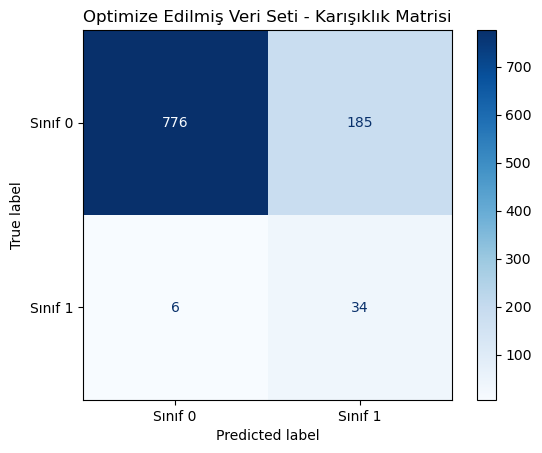

In [17]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Sınıflandırma raporu
print("\nSınıflandırma Raporu:\n", classification_report(y_test, y_pred_optimized))

# Karışıklık matrisi
cm_optimized = confusion_matrix(y_test, y_pred_optimized)
disp_optimized = ConfusionMatrixDisplay(cm_optimized, display_labels=["Sınıf 0", "Sınıf 1"])
disp_optimized.plot(cmap="Blues")
plt.title("Optimize Edilmiş Veri Seti - Karışıklık Matrisi")
plt.show()


### 18. Veri Dengesi Sağlama

Bu kod parçasıyla, eğitim veri setimdeki sınıf dengesizliğini gidermeyi amaçlıyorum. Bunun için SMOTE (Synthetic Minority Oversampling Technique) yöntemini kullanarak, azınlık sınıflar için yapay örnekler oluşturuyorum. Böylece, sınıflar arasında dengeli bir dağılım elde ediyorum. İşlem sonucunda dengeli veri setimi (X_train_balanced ve y_train_balanced) oluşturuyor ve sınıf dağılımını (Counter) kontrol ederek dengelemenin başarıyla gerçekleştiğini doğruluyorum. Bu adım, modelimin dengesiz veri setinden kaynaklanan öğrenme sorunlarını önlemeye ve tüm sınıflar için daha iyi bir performans sergilemesini sağlamaya yardımcı oluyor.

In [18]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# SMOTE ile veri dengesi oluşturma
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_sm_optimized, y_train_sm)

# Dengeli veri setindeki sınıf dağılımını kontrol etme
print("Sınıf Dağılımı (SMOTE Sonrası):", Counter(y_train_balanced))


Sınıf Dağılımı (SMOTE Sonrası): Counter({0: 3820, 1: 3820})


### 19. Modeli SMOTE Sonrası Veri ile Eğitme

Bu kod parçasıyla, **SMOTE** yöntemi ile dengelenmiş veri setini kullanarak modelimi yeniden eğitiyorum. İlk olarak, **SMOTE sonrası dengelenmiş eğitim verisini** (`X_train_balanced`, `y_train_balanced`) kullanarak, en iyi hiperparametrelerle (`svc_grid.best_params_`) **SVC modelini** eğitiyorum. Sonrasında, optimize edilmiş test veri seti üzerinde (`X_test_optimized`) tahminler yaparak yeni doğruluk oranını hesaplıyorum. Sonuç olarak, dengelenmiş veri ile elde edilen doğruluk oranını yazdırıyorum. Bu adım, veri dengesinin model performansını nasıl etkilediğini görmek ve sınıf dengesizliğinin yol açtığı olumsuz etkileri gidermek için oldukça önemli.

In [19]:
# SMOTE sonrası veri ile modeli eğitme
svc_balanced_model = SVC(**svc_grid.best_params_, random_state=42)
svc_balanced_model.fit(X_train_balanced, y_train_balanced)

# Yeni modelin tahminlerini yapma
y_pred_balanced = svc_balanced_model.predict(X_test_optimized)

# Yeni doğruluk oranı
balanced_accuracy = accuracy_score(y_test, y_pred_balanced)
print("Dengeli Veri ile Doğruluk Oranı:", balanced_accuracy)


Dengeli Veri ile Doğruluk Oranı: 0.8091908091908092


### 20. Performansı Yeniden Değerlendirme

Bu kod parçasıyla, **SMOTE sonrası dengelenmiş veriyle** eğitilmiş modelimin performansını yeniden değerlendiriyorum. İlk olarak, modelin her bir sınıf için doğruluk, hassasiyet, f1 puanı ve çağrı oranını içeren **sınıflandırma raporunu** (`classification_report`) oluşturuyorum. Bu rapor, modelin tüm sınıflarda nasıl performans gösterdiğini detaylı bir şekilde ortaya koyuyor. Ardından, modelin tahmin sonuçlarını görselleştirmek için **karışıklık matrisi**ni (`confusion_matrix`) hesaplıyorum ve görsel olarak sunuyorum (`ConfusionMatrixDisplay`). Karışıklık matrisi, modelin her bir sınıf için doğru ve yanlış sınıflandırmalarını net bir şekilde gösteriyor ve modelin gücünü ve zayıf yönlerini anlamamı sağlıyor. Bu analiz, sınıf dengesizliğinin düzeltilmesinin model performansını nasıl etkilediğini daha iyi değerlendirmeme yardımcı oluyor.


Dengeli Veri Sonrası Sınıflandırma Raporu:
               precision    recall  f1-score   support

           0       0.99      0.81      0.89       961
           1       0.16      0.85      0.26        40

    accuracy                           0.81      1001
   macro avg       0.57      0.83      0.58      1001
weighted avg       0.96      0.81      0.87      1001



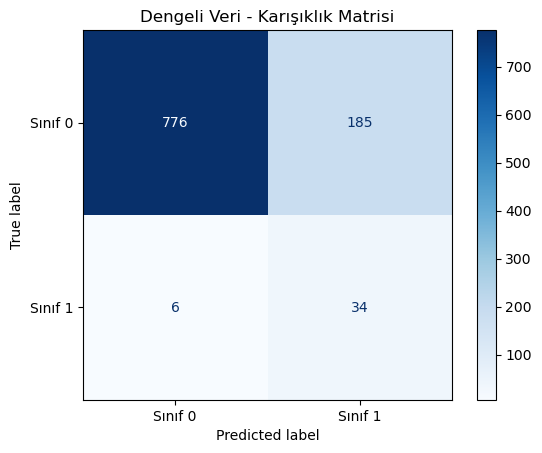

In [20]:
# Yeni sınıflandırma raporu ve karışıklık matrisi
print("\nDengeli Veri Sonrası Sınıflandırma Raporu:\n", classification_report(y_test, y_pred_balanced))

cm_balanced = confusion_matrix(y_test, y_pred_balanced)
disp_balanced = ConfusionMatrixDisplay(cm_balanced, display_labels=["Sınıf 0", "Sınıf 1"])
disp_balanced.plot(cmap="Blues")
plt.title("Dengeli Veri - Karışıklık Matrisi")
plt.show()


### 21. Dengeli ve Dengesiz Verilerin Performans Değerlerini Karşılaştırma

Bu kod parçası ile, **dengesiz ve dengeli veri kümelerinin performansını karşılaştırmak** istiyorum. İlk olarak, **dengesiz veri** ile eğitim yaparak modelimi oluşturuyorum ve ardından **SMOTE** ile **dengeli veri** oluşturup başka bir model eğitiyorum. Sonrasında her iki modelin **test veri seti üzerinde tahminlerini** yapıyorum. Performansı değerlendirmek için **classification_report** fonksiyonunu kullanarak her iki modelin de çeşitli metriklerini (doğruluk, hassasiyet, hatırlama oranı, F1 skoru) alıyorum. Bu metrikleri daha sonra bir karşılaştırma tablosuna yerleştiriyorum. Bu karşılaştırma, dengeli veri kullanmanın model performansındaki etkisini anlamama yardımcı olacak ve hangi yaklaşımın daha iyi sonuç verdiğini değerlendirmemi sağlayacak.

In [21]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Örnek veri oluşturun (Bu kısmı kendi verinize göre değiştirin)
# Örneğin, X ve y burada sizin veri kümeniz olmalı
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, weights=[0.9, 0.1], random_state=42)

# Eğitim ve test verilerini ayırma
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Dengesiz veri modeli oluştur ve eğit
model_imbalanced = RandomForestClassifier(random_state=42)
model_imbalanced.fit(X_train, y_train)

# SMOTE kullanarak dengeli veri oluştur
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# Dengeli veri modeli oluştur ve eğit
model_balanced = RandomForestClassifier(random_state=42)
model_balanced.fit(X_train_balanced, y_train_balanced)

# Test seti üzerinde tahmin yapın (dengesiz veri modeliyle)
y_pred = model_imbalanced.predict(X_test)

# Test seti üzerinde tahmin yapın (dengeli veri modeliyle)
y_pred_balanced = model_balanced.predict(X_test)

# Dengesiz veri metriklerini al
imbalanced_report = classification_report(y_test, y_pred, output_dict=True)

# Dengeli veri metriklerini al
balanced_report = classification_report(y_test, y_pred_balanced, output_dict=True)

# Önemli metrikleri seçelim
metrics = ["precision", "recall", "f1-score", "accuracy"]
classes = ["0", "1"]

# Verileri tabloya yerleştir
comparison_data = []
for metric in metrics:
    if metric == "accuracy":
        imbalanced_value = imbalanced_report["accuracy"]
        balanced_value = balanced_report["accuracy"]
    else:
        imbalanced_value = sum(imbalanced_report[c][metric] for c in classes) / len(classes)
        balanced_value = sum(balanced_report[c][metric] for c in classes) / len(classes)
    comparison_data.append([metric, imbalanced_value, balanced_value])

# DataFrame oluştur
comparison_df = pd.DataFrame(comparison_data, columns=["Metric", "Imbalanced", "Balanced"])

# Tabloyu göster
print(comparison_df)


      Metric  Imbalanced  Balanced
0  precision    0.921053  0.841880
1     recall    0.722222  0.811111
2   f1-score    0.783784  0.825531
3   accuracy    0.940000  0.940000


### 22. Performans Karşılaştırmasını Görselleştirme

Bu kod parçası ile, **dengesiz ve dengeli veri kümelerinin performans karşılaştırmasını görselleştirmek** istiyorum. İlk olarak, her iki modelin performans metriklerini içeren karşılaştırma verilerini (`comparison_df`) kullanarak görsel bir **çubuk grafik** oluşturuyorum. Çubuklar, her iki modelin performansını bir arada gösterecek şekilde yerleştiriliyor; **dengesiz modelin skorları** mavi renk ile, **dengeli modelin skorları** ise yeşil renk ile gösteriliyor. X ekseninde metrikler yer alırken, Y ekseninde bu metriklere karşılık gelen performans skorları (0-1 arası) bulunuyor. Grafikte başlık, etiketler, grid ve legend ekleyerek görselliği artırıyor ve performans farklarını net bir şekilde gözler önüne seriyorum. Bu görselleştirme, hangi modelin daha iyi performans gösterdiğini hızlıca anlamama yardımcı olacaktır.

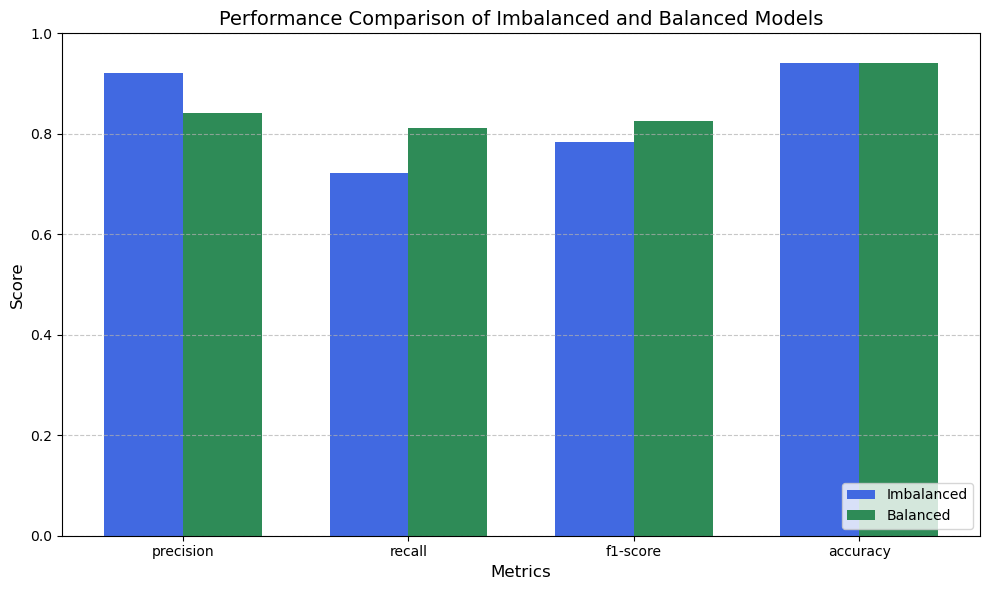

In [22]:
import matplotlib.pyplot as plt

# Performans karşılaştırmasını görselleştirme
metrics = comparison_df["Metric"]
imbalanced_scores = comparison_df["Imbalanced"]
balanced_scores = comparison_df["Balanced"]

x = range(len(metrics))

plt.figure(figsize=(10, 6))
bar_width = 0.35

# Dengesiz modelin performans değerlerini çizin
plt.bar(x, imbalanced_scores, width=bar_width, label="Imbalanced", color="royalblue")

# Dengeli modelin performans değerlerini çizin
plt.bar([p + bar_width for p in x], balanced_scores, width=bar_width, label="Balanced", color="seagreen")

# X ekseni için metrikleri ekleyin
plt.xticks([p + bar_width / 2 for p in x], metrics)

# Grafiğin başlığı ve etiketleri
plt.title("Performance Comparison of Imbalanced and Balanced Models", fontsize=14)
plt.xlabel("Metrics", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.ylim(0, 1)  # Skorların 0-1 arasında olduğunu varsayıyoruz

# Legend ve grid ekleyin
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Grafiği göster
plt.tight_layout()
plt.show()


### 23. SVC ve Lojistik Regresyon Modelleri ile Çapraz Doğrulama ve Performans Karşılaştırması

Bu kod parçası ile, **SVC ve Lojistik Regresyon modelleri arasında çapraz doğrulama kullanarak performans karşılaştırması yapmayı** hedefliyorum. İlk adımda, örnek bir veri kümesi olarak `load_digits` kullanarak veriyi hazırlıyorum ve eğitim ve test setlerine ayırıyorum. Sonrasında, her iki model için **5 katlı çapraz doğrulama** (5-fold cross-validation) uygulayarak doğruluk oranlarını hesaplıyorum. Bu doğrulukları görselleştirmek için iki ayrı **çubuk grafik** oluşturuyorum: birisi SVC modelinin doğruluk değerlerini, diğeri ise Lojistik Regresyon modelinin doğruluk değerlerini gösteriyor. Grafikte, her bir katın doğruluğu karşılaştırılabilir bir şekilde görselleştiriliyor. Ayrıca, her modelin **ortalama doğruluğunu** hesaplayarak bu bilgiyi yazdırıyorum. Son olarak, her iki modelin **performanslarını karşılaştıran bir grafik** oluşturuyorum, böylece hangi modelin daha iyi performans gösterdiğini net bir şekilde gözlemleyebiliyorum.

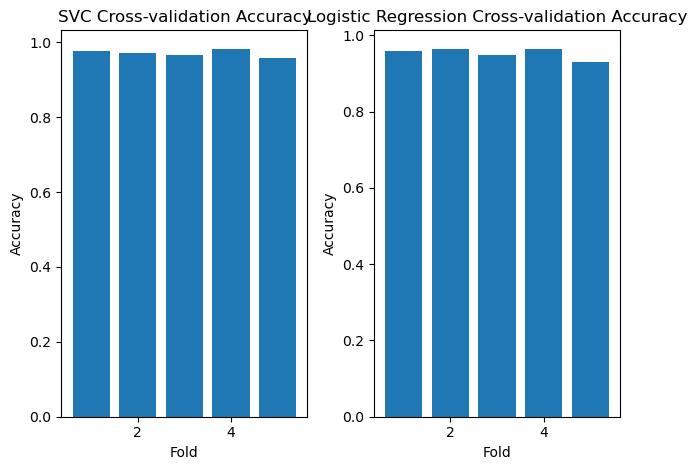

SVC Modeli Ortalama Doğruluk: 97.08%
Logistic Regression Ortalama Doğruluk: 95.34%


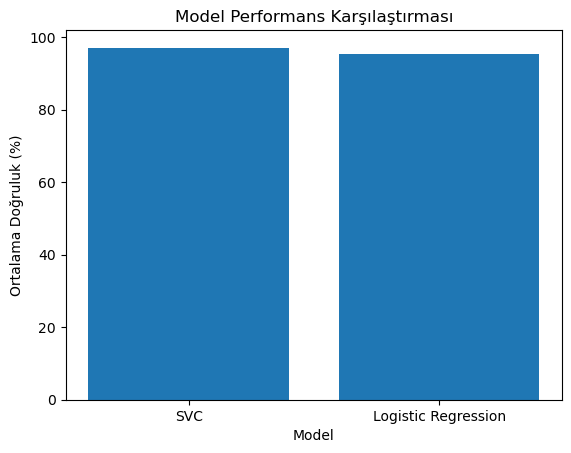

In [23]:
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_digits  # Örnek bir veri kümesi, kendi veri kümenizle değiştirin

# 1. Veri Hazırlığı
# Örnek veri kümesi olarak load_digits kullanalım
digits = load_digits()
X = digits.data  # Özellikler
y = digits.target  # Etiketler

# Eğitim ve test verilerini ayıralım
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. 5 Katlı Çapraz Doğrulama ve Modelleri Eğitme
svc = SVC(kernel='linear')  # SVC modelini oluştur
lr = LogisticRegression(max_iter=10000)  # Lojistik regresyon modelini oluştur

# 5 Katlı çapraz doğrulama kullanarak doğruluk hesaplama
svc_accuracy = cross_val_score(svc, X_train, y_train, cv=5, scoring='accuracy')
lr_accuracy = cross_val_score(lr, X_train, y_train, cv=5, scoring='accuracy')

# 3. Sonuçları Görselleştirme
import matplotlib.pyplot as plt

# SVC doğrulukları
plt.subplot(1, 2, 1)
plt.bar(range(1, 6), svc_accuracy)
plt.title('SVC Cross-validation Accuracy')
plt.xlabel('Fold')
plt.ylabel('Accuracy')

# Logistic Regression doğrulukları
plt.subplot(1, 2, 2)
plt.bar(range(1, 6), lr_accuracy)
plt.title('Logistic Regression Cross-validation Accuracy')
plt.xlabel('Fold')
plt.ylabel('Accuracy')

plt.tight_layout()
plt.show()

# 4. Ortalama Doğrulukları Yazdırma
svc_mean_accuracy = np.mean(svc_accuracy) * 100
lr_mean_accuracy = np.mean(lr_accuracy) * 100

print(f'SVC Modeli Ortalama Doğruluk: {svc_mean_accuracy:.2f}%')
print(f'Logistic Regression Ortalama Doğruluk: {lr_mean_accuracy:.2f}%')

# 5. Model Performans Karşılaştırması
models = ['SVC', 'Logistic Regression']
accuracies = [svc_mean_accuracy, lr_mean_accuracy]

plt.figure()
plt.bar(models, accuracies)
plt.title('Model Performans Karşılaştırması')
plt.xlabel('Model')
plt.ylabel('Ortalama Doğruluk (%)')
plt.show()


### 24. Model Karşılaştırması (Doğruluk, Hata Oranı, İşlem Süresi)

  Bu kod parçası ile SVC ve Lojistik Regresyon modelleri arasındaki performans karşılaştırmasını yapmayı amaçlıyorum. İlk olarak her iki modelin de eğitim ve test süreçlerini ölçüyorum. Bu süreçte her model için doğruluk, hata oranı ve işlem süresi gibi metrikleri hesaplıyorum.
  Sonrasında, doğruluk, hata oranı ve işlem süresi karşılaştırmalarını görselleştiren üç farklı çubuk grafik oluştururum. Bu grafiklerde her iki modelin karşılaştırmalı sonuçlarını görsel olarak inceleyebilirsiniz.

  Son olarak, her iki modelin doğruluk, hata oranı ve işlem süresi ile ilgili sayısal sonuçlar yazdırılır. Bu sayede hangi modelin daha hızlı ve etkili olduğunu karşılaştırabilirsiniz.

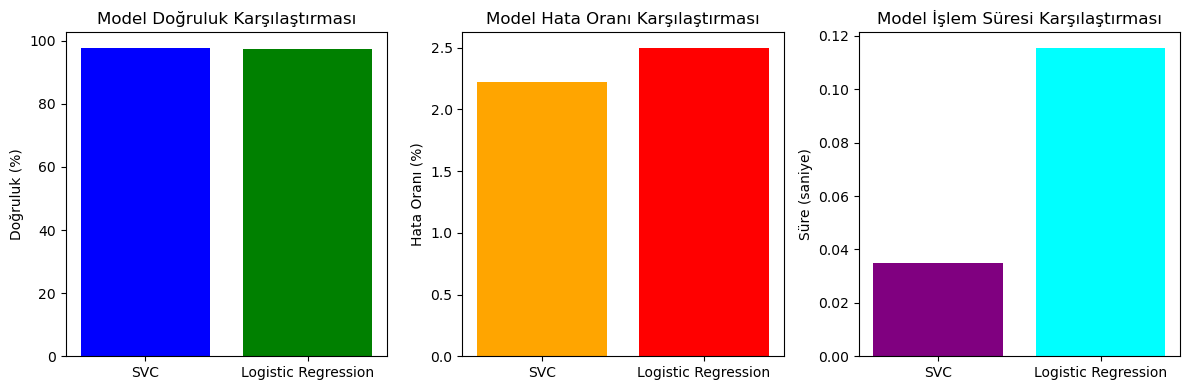

SVC Doğruluk: 97.78%, Hata Oranı: 2.22%, Süre: 0.0351 saniye
Logistic Regression Doğruluk: 97.50%, Hata Oranı: 2.50%, Süre: 0.1156 saniye


In [24]:
import time  # İşlem süresini ölçmek için
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. SVC Modelinin Performans Ölçümü
svc_start_time = time.time()  # Başlangıç zamanını kaydet
svc.fit(X_train, y_train)  # Modeli eğit
svc_pred = svc.predict(X_test)  # Test verileri üzerinde tahmin yap
svc_end_time = time.time()  # Bitiş zamanını kaydet

svc_accuracy_score = accuracy_score(y_test, svc_pred)  # Doğruluk hesaplama
svc_error_rate = 1 - svc_accuracy_score  # Hata oranı
svc_time = svc_end_time - svc_start_time  # İşlem süresi

# 2. Logistic Regression Modelinin Performans Ölçümü
lr_start_time = time.time()  # Başlangıç zamanını kaydet
lr.fit(X_train, y_train)  # Modeli eğit
lr_pred = lr.predict(X_test)  # Test verileri üzerinde tahmin yap
lr_end_time = time.time()  # Bitiş zamanını kaydet

lr_accuracy_score = accuracy_score(y_test, lr_pred)  # Doğruluk hesaplama
lr_error_rate = 1 - lr_accuracy_score  # Hata oranı
lr_time = lr_end_time - lr_start_time  # İşlem süresi

# 3. Sonuçları Karşılaştırma ve Görselleştirme
models = ['SVC', 'Logistic Regression']
accuracies = [svc_accuracy_score * 100, lr_accuracy_score * 100]
error_rates = [svc_error_rate * 100, lr_error_rate * 100]
times = [svc_time, lr_time]

# Doğruluk karşılaştırması
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.bar(models, accuracies, color=['blue', 'green'])
plt.title('Model Doğruluk Karşılaştırması')
plt.ylabel('Doğruluk (%)')

# Hata oranı karşılaştırması
plt.subplot(1, 3, 2)
plt.bar(models, error_rates, color=['orange', 'red'])
plt.title('Model Hata Oranı Karşılaştırması')
plt.ylabel('Hata Oranı (%)')

# İşlem süresi karşılaştırması
plt.subplot(1, 3, 3)
plt.bar(models, times, color=['purple', 'cyan'])
plt.title('Model İşlem Süresi Karşılaştırması')
plt.ylabel('Süre (saniye)')

plt.tight_layout()
plt.show()

# 4. Sonuçları Yazdırma
print(f"SVC Doğruluk: {svc_accuracy_score * 100:.2f}%, Hata Oranı: {svc_error_rate * 100:.2f}%, Süre: {svc_time:.4f} saniye")
print(f"Logistic Regression Doğruluk: {lr_accuracy_score * 100:.2f}%, Hata Oranı: {lr_error_rate * 100:.2f}%, Süre: {lr_time:.4f} saniye")


### 25. Optimizasyon Sonrası Sonuçları Karşılaştırma

 Bu kodda, SVC ve Lojistik Regresyon modellerini GridSearchCV kullanarak optimize ettim. Öncelikle her iki modelin hiperparametrelerini optimize etmek için farklı parametre değerlerini denedim ve en iyi performansı veren parametre kombinasyonlarını buldum. Sonrasında bu optimize edilmiş modelleri test verisi üzerinde çalıştırarak doğruluk ve hata oranlarını hesapladım.

Son olarak, optimizasyon öncesi ve sonrası elde ettiğim doğruluk ve hata oranlarını karşılaştırdım. Performans farklarını görsel olarak karşılaştırmak için bar grafikleri oluşturdum ve her iki modelin optimize edilmeden önceki ve sonrasındaki performans farklarını detaylı şekilde gözlemledim.

Grafikler ve yazdırdığım sonuçlarla, optimizasyonun model performansına nasıl bir etkisi olduğunu daha net bir şekilde gözlemleyebildim.

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Fitting 5 folds for each of 6 candidates, totalling 30 fits


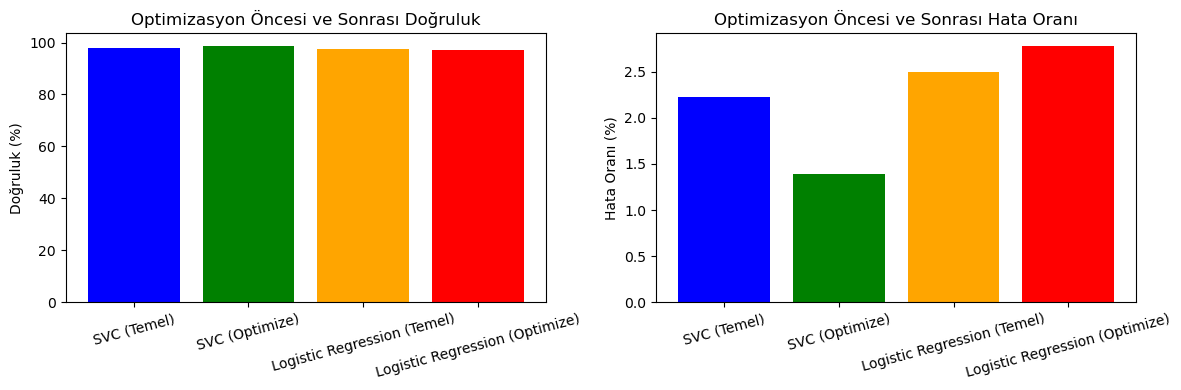

SVC (Optimize Edilmiş) Doğruluk: 98.61%, Hata Oranı: 1.39%
Logistic Regression (Optimize Edilmiş) Doğruluk: 97.22%, Hata Oranı: 2.78%


In [25]:
from sklearn.model_selection import GridSearchCV

# 1. SVC Optimizasyonu
svc_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
svc_grid = GridSearchCV(SVC(), svc_params, cv=5, scoring='accuracy', verbose=1)
svc_grid.fit(X_train, y_train)

optimized_svc = svc_grid.best_estimator_  # En iyi modeli al
svc_optimized_pred = optimized_svc.predict(X_test)  # Optimize edilmiş modelin tahminleri

svc_optimized_accuracy = accuracy_score(y_test, svc_optimized_pred)
svc_optimized_error_rate = 1 - svc_optimized_accuracy

# 2. Logistic Regression Optimizasyonu
lr_params = {'C': [0.1, 1, 10], 'solver': ['lbfgs', 'liblinear']}
lr_grid = GridSearchCV(LogisticRegression(max_iter=10000), lr_params, cv=5, scoring='accuracy', verbose=1)
lr_grid.fit(X_train, y_train)

optimized_lr = lr_grid.best_estimator_  # En iyi modeli al
lr_optimized_pred = optimized_lr.predict(X_test)  # Optimize edilmiş modelin tahminleri

lr_optimized_accuracy = accuracy_score(y_test, lr_optimized_pred)
lr_optimized_error_rate = 1 - lr_optimized_accuracy

# 3. Optimizasyon Öncesi ve Sonrası Karşılaştırma
models = ['SVC (Temel)', 'SVC (Optimize)', 'Logistic Regression (Temel)', 'Logistic Regression (Optimize)']
accuracies = [
    svc_accuracy_score * 100,
    svc_optimized_accuracy * 100,
    lr_accuracy_score * 100,
    lr_optimized_accuracy * 100,
]
error_rates = [
    svc_error_rate * 100,
    svc_optimized_error_rate * 100,
    lr_error_rate * 100,
    lr_optimized_error_rate * 100,
]

# Doğruluk karşılaştırması
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.bar(models, accuracies, color=['blue', 'green', 'orange', 'red'])
plt.title('Optimizasyon Öncesi ve Sonrası Doğruluk')
plt.ylabel('Doğruluk (%)')
plt.xticks(rotation=15)

# Hata oranı karşılaştırması
plt.subplot(1, 2, 2)
plt.bar(models, error_rates, color=['blue', 'green', 'orange', 'red'])
plt.title('Optimizasyon Öncesi ve Sonrası Hata Oranı')
plt.ylabel('Hata Oranı (%)')
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

# 4. Sonuçları Yazdırma
print(f"SVC (Optimize Edilmiş) Doğruluk: {svc_optimized_accuracy * 100:.2f}%, Hata Oranı: {svc_optimized_error_rate * 100:.2f}%")
print(f"Logistic Regression (Optimize Edilmiş) Doğruluk: {lr_optimized_accuracy * 100:.2f}%, Hata Oranı: {lr_optimized_error_rate * 100:.2f}%")
